## Final Insights & Business Recommendations

In this notebook, I will summarize the key findings from the diabetes hospital readmission analysis.

The goal is to understand which factors are associated with 30-day hospital readmission and translate the machine learning results into useful business and healthcare insights.

**Import Libraries**

In [27]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
# Load the Data
df = pd.read_csv(
    "../data/processed/model_ready_data.csv"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)


# Check the Data
df.head()

Dataset loaded successfully!
Shape: (101766, 21)


,race,gender,age,admission_type_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,...,number_inpatient,number_diagnoses,max_glu_serum,A1Cresult,change,diabetesMed,total_previous_visits,total_procedures,readmitted_30_days,patient_nbr
0,Caucasian,Female,[0-10),6,1,1,41,0,1,0,...,0,1,NaN,NaN,No,No,0,41,0,8222157
1,Caucasian,Female,[10-20),1,7,3,59,0,18,0,...,0,9,NaN,NaN,Ch,Yes,0,59,0,55629189
2,AfricanAmerican,Female,[20-30),1,7,2,11,5,13,2,...,1,6,NaN,NaN,No,Yes,3,16,0,86047875
3,Caucasian,Male,[30-40),1,7,2,44,1,16,0,...,0,7,NaN,NaN,Ch,Yes,0,45,0,82442376
4,Caucasian,Male,[40-50),1,7,1,51,0,8,0,...,0,5,NaN,NaN,Ch,Yes,0,51,0,42519267


**Overall Readmission Rate**

In [29]:
readmission_counts = df["readmitted_30_days"].value_counts()

print(readmission_counts)

readmitted_30_days
0    90409
1    11357
Name: count, dtype: int64


In [30]:
# Percentage of patients readmitted within 30 days
readmission_rate = (
    df["readmitted_30_days"].mean() * 100
)

print(
    "30-day readmission rate:",
    round(readmission_rate, 2),
    "%"
)


30-day readmission rate: 11.16 %


In [31]:
# I first calculated the overall 30-day readmission rate to understand the size of the problem in the dataset.

**Readmission Distribution**

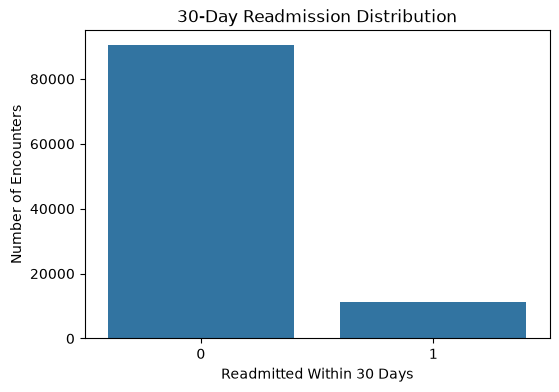

In [32]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="readmitted_30_days"
)

plt.title("30-Day Readmission Distribution")
plt.xlabel("Readmitted Within 30 Days")
plt.ylabel("Number of Encounters")

plt.show()

**Readmission by Age**

In [33]:
age_readmission = (
    df.groupby("age")["readmitted_30_days"]
    .mean()
    .mul(100)
    .reset_index()
)

age_readmission.columns = [
    "Age Group",
    "Readmission Rate"
]

age_readmission

,Age Group,Readmission Rate
0,[0-10),1.863354
1,[10-20),5.788712
2,[20-30),14.242607
3,[30-40),11.231788
4,[40-50),10.604027
5,[50-60),9.666203
6,[60-70),11.128408
7,[70-80),11.773055
8,[80-90),12.083503
9,[90-100),11.099177


**Visualize Readmission by Age**

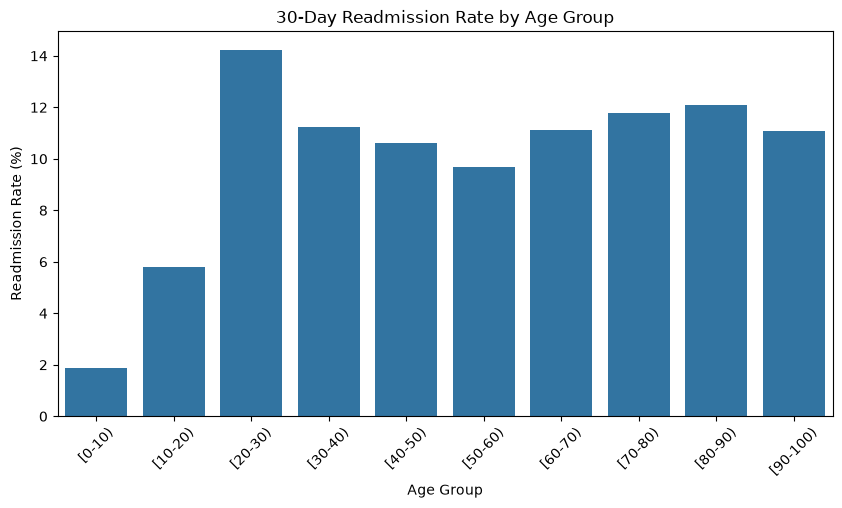

In [34]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_readmission,
    x="Age Group",
    y="Readmission Rate"
)

plt.title("30-Day Readmission Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Readmission Rate (%)")

plt.xticks(rotation=45)

plt.show()

**Readmission by Gender**

In [35]:
gender_readmission = (
    df.groupby("gender")["readmitted_30_days"]
    .mean()
    .mul(100)
    .reset_index()
)

gender_readmission.columns = [
    "Gender",
    "Readmission Rate"
]

gender_readmission

,Gender,Readmission Rate
0,Female,11.245156
1,Male,11.061524
2,Unknown/Invalid,0.000000


**Visualize Gender Results**

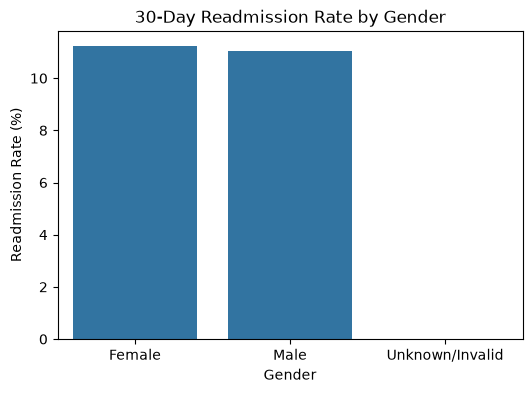

In [36]:
plt.figure(figsize=(6, 4))

sns.barplot(
    data=gender_readmission,
    x="Gender",
    y="Readmission Rate"
)

plt.title("30-Day Readmission Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Readmission Rate (%)")

plt.show()

**Readmission by Hospital Stay**

In [37]:
stay_readmission = (
    df.groupby("time_in_hospital")["readmitted_30_days"]
    .mean()
    .mul(100)
    .reset_index()
)

stay_readmission.columns = [
    "Days in Hospital",
    "Readmission Rate"
]

stay_readmission.head(10)

,Days in Hospital,Readmission Rate
0,1,8.178491
1,2,9.939619
2,3,10.666817
3,4,11.806952
4,5,12.030905
5,6,12.587876
6,7,12.834955
7,8,14.233660
8,9,13.724184
9,10,14.346712


**Visualize Hospital Stay**

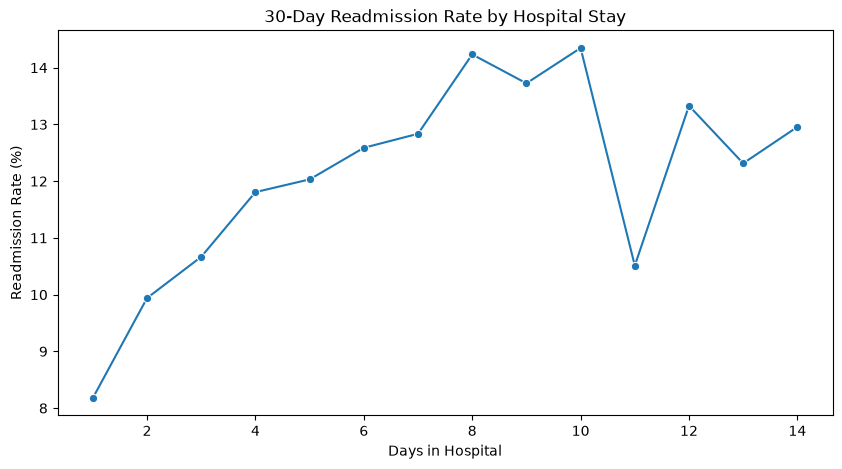

In [38]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=stay_readmission,
    x="Days in Hospital",
    y="Readmission Rate",
    marker="o"
)

plt.title(
    "30-Day Readmission Rate by Hospital Stay"
)

plt.xlabel("Days in Hospital")
plt.ylabel("Readmission Rate (%)")

plt.show()

**Readmission by Previous Healthcare Visits**

In [39]:
# We created this feature in Notebook 3:
# total_previous_visits

visit_readmission = (
    df.groupby("total_previous_visits")[
        "readmitted_30_days"
    ]
    .mean()
    .mul(100)
    .reset_index()
)

visit_readmission.columns = [
    "Previous Visits",
    "Readmission Rate"
]

visit_readmission.head(15)

,Previous Visits,Readmission Rate
0,0,8.175109
1,1,11.564114
2,2,14.619360
3,3,15.277778
4,4,17.114846
5,5,18.369352
6,6,23.229246
7,7,22.695853
8,8,24.548736
9,9,27.441860


**Visualize Previous Visits**

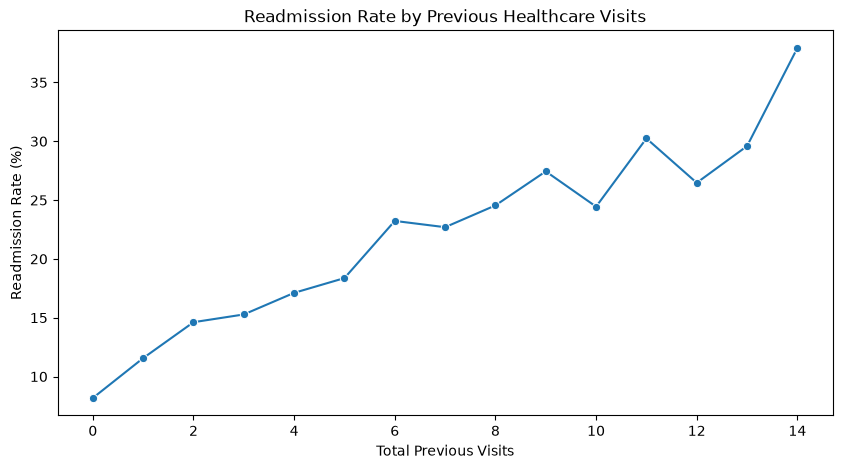

In [40]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=visit_readmission.head(15),
    x="Previous Visits",
    y="Readmission Rate",
    marker="o"
)

plt.title(
    "Readmission Rate by Previous Healthcare Visits"
)

plt.xlabel("Total Previous Visits")
plt.ylabel("Readmission Rate (%)")

plt.show()

**Readmission by Diabetes Medication**

In [41]:
medication_readmission = (
    df.groupby("diabetesMed")[
        "readmitted_30_days"
    ]
    .mean()
    .mul(100)
    .reset_index()
)

medication_readmission.columns = [
    "Diabetes Medication",
    "Readmission Rate"
]

medication_readmission

,Diabetes Medication,Readmission Rate
0,No,9.597060
1,Yes,11.626661


**Visualize Medication Results**

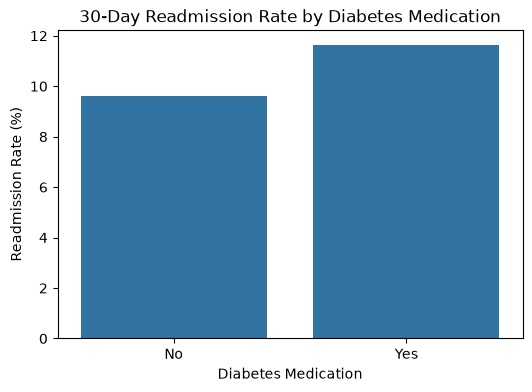

In [42]:
plt.figure(figsize=(6, 4))

sns.barplot(
    data=medication_readmission,
    x="Diabetes Medication",
    y="Readmission Rate"
)

plt.title(
    "30-Day Readmission Rate by Diabetes Medication"
)

plt.xlabel("Diabetes Medication")
plt.ylabel("Readmission Rate (%)")

plt.show()

**Load Model Comparison**

In [43]:
comparison = pd.read_csv(
    "../results/model_comparison.csv"
)

comparison

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.674651,0.164446,0.500692,0.247578,0.641842
1,Random Forest,0.880132,0.255121,0.063163,0.101256,0.600963


**Display Final Model Performance**

In [44]:
comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.675,0.164,0.501,0.248,0.642
1,Random Forest,0.880,0.255,0.063,0.101,0.601


**Identify Best Model**

In [45]:
best_model_f1 = comparison.loc[
    comparison["F1 Score"].idxmax(),
    "Model"
]

best_model_auc = comparison.loc[
    comparison["ROC-AUC"].idxmax(),
    "Model"
]

print(
    "Best model based on F1 Score:",
    best_model_f1
)

print(
    "Best model based on ROC-AUC:",
    best_model_auc
)

Best model based on F1 Score: Logistic Regression
Best model based on ROC-AUC: Logistic Regression


**Load Feature Importance**

In [46]:
import joblib

random_forest_model = joblib.load(
    "../models/random_forest_model.pkl"
)

In [47]:
rf_preprocessor = (
    random_forest_model
    .named_steps["preprocessor"]
)

rf_model = (
    random_forest_model
    .named_steps["model"]
)

**Create Feature Importance Table**

In [48]:
feature_names = (
    rf_preprocessor
    .get_feature_names_out()
)

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = (
    feature_importance
    .sort_values(
        by="Importance",
        ascending=False
    )
)

feature_importance.head(15)

,Feature,Importance
11,num__total_procedures,0.131074
3,num__num_lab_procedures,0.130618
5,num__num_medications,0.128690
2,num__time_in_hospital,0.086268
4,num__num_procedures,0.060477
9,num__number_diagnoses,0.057374
0,num__admission_type_id,0.041301
10,num__total_previous_visits,0.040379
8,num__number_inpatient,0.037916
1,num__admission_source_id,0.035208


**Plot Top Features**

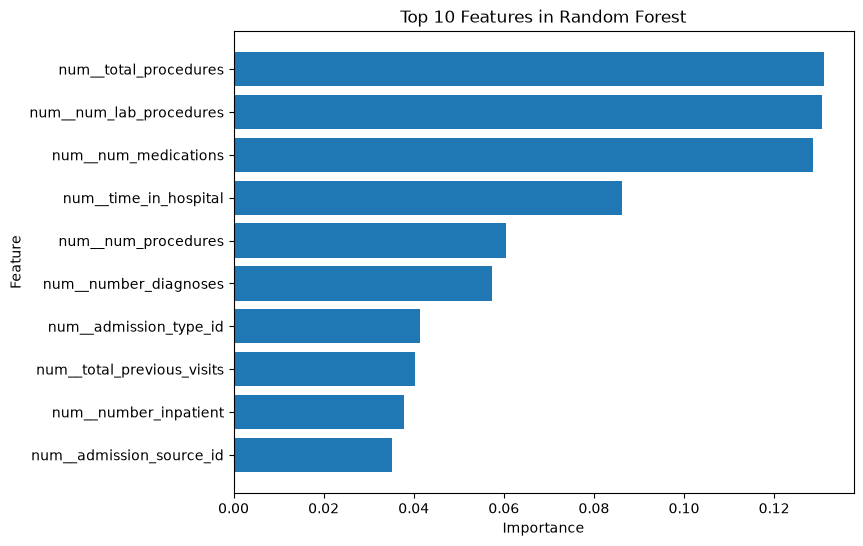

In [49]:
top_features = feature_importance.head(10)

plt.figure(figsize=(8, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")

plt.title(
    "Top 10 Features in Random Forest"
)

plt.show()

**Create Final Insights Table**

In [50]:
final_insights = pd.DataFrame({
    "Area": [
        "Overall Readmission",
        "Age",
        "Hospital Stay",
        "Previous Healthcare Visits",
        "Diabetes Medication"
    ],
    "Analysis": [
        "Overall 30-day readmission rate",
        "Readmission rate by age group",
        "Readmission rate by hospital stay",
        "Readmission rate by previous visits",
        "Readmission rate by diabetes medication"
    ]
})

final_insights

,Area,Analysis
0,Overall Readmission,Overall 30-day readmission rate
1,Age,Readmission rate by age group
2,Hospital Stay,Readmission rate by hospital stay
3,Previous Healthcare Visits,Readmission rate by previous visits
4,Diabetes Medication,Readmission rate by diabetes medication


## Business and Healthcare Recommendations

Based on the analysis, the following recommendations can be considered:

1. **Identify high-risk patients early**
   - Use the model to help identify patients who may have a higher risk of 30-day readmission.

2. **Focus on patients with previous healthcare utilization**
   - Patients with higher numbers of previous visits can be reviewed more carefully during discharge planning.

3. **Use patient and encounter information together**
   - Factors such as age, hospital stay, previous visits, diagnoses, and procedures can provide useful information for risk assessment.

4. **Improve discharge planning**
   - Higher-risk patients may benefit from stronger follow-up planning, medication review, and post-discharge support.

5. **Use the model as a decision-support tool**
   - The model should support healthcare professionals rather than replace clinical judgment.

## Project Limitations

There are several limitations to this analysis:

- The dataset contains historical hospital encounter data from 1999–2008.
- The dataset may not represent current healthcare practices.
- The analysis identifies associations and does not prove causation.
- The target variable is imbalanced.
- The model should not be used as a replacement for clinical judgment.
- Additional validation would be required before using the model in a real healthcare environment.
- More recent and diverse healthcare data could improve the analysis.

# Final Project Summary

## Project Objective

The objective of this project was to analyze diabetes hospital encounter data and build a machine learning model to predict whether a patient would be readmitted within 30 days.

## Data Preparation

I cleaned the dataset, handled missing values, explored the data, analyzed potential outliers, studied correlations, and created additional features such as total previous visits and total procedures.

## Machine Learning

I trained two classification models:

- Logistic Regression
- Random Forest

I used a patient-level train/test split to reduce the risk of data leakage.

## Model Evaluation

I evaluated the models using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- Confusion Matrix
- ROC Curve

Because the target variable was imbalanced, I considered multiple evaluation metrics rather than relying only on accuracy.

## Key Insights

The analysis helped identify patterns between 30-day readmission and factors such as age, hospital stay, previous healthcare utilization, medication information, and other patient encounter characteristics.

## Business Value

The analysis can help healthcare organizations explore potential high-risk patients and support better discharge planning and follow-up strategies.

The model should be considered a decision-support tool and would require additional validation before real-world healthcare use.

**Save Final Insights**

In [51]:
from pathlib import Path

results_folder = Path("../results")

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

feature_importance.to_csv(
    results_folder / "feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


# Project Completed 🎉

This project followed a complete data analytics and machine learning workflow:

1. Data Understanding
2. Data Cleaning and EDA
3. Outlier Analysis, Correlation and Feature Engineering
4. Model Training
5. Model Evaluation
6. Final Insights and Recommendations

The project demonstrates skills in:

- Python
- Pandas
- NumPy
- Data Cleaning
- Exploratory Data Analysis
- Feature Engineering
- Data Visualization
- SQL/analytics thinking
- Machine Learning
- Model Evaluation
- Business Insights